In [77]:
from langgraph.graph import StateGraph
from typing import TypedDict, Literal
from langchain_ollama import ChatOllama
from pydantic import BaseModel, Field
from langgraph.constants import START, END
from langchain_core.prompts import PromptTemplate

In [78]:
model= ChatOllama(
    model="qwen2.5-coder:3b", temperature=0.3
)

In [79]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative"]= Field(description="sentiment of the review")



In [80]:
class ResponseSchema(BaseModel):
    response: str = Field("Response of the review")

In [81]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "bug","UI", "responsiveness", "others"] = Field(description="The type of issu customer is facing")
    tone: Literal["Angry", "Frustated","Calm","Dissapointed"] = Field(description="The emotional tone of the customer")
    urgency: Literal["Low", "Medium", "High"] = Field(description="How urgent or critical the issue is")

In [82]:
sentiment_structured_model= model.with_structured_output(SentimentSchema)
response_structured_model= model.with_structured_output(ResponseSchema)
diagnosis_structured_model= model.with_structured_output(DiagnosisSchema)

In [83]:
class ReviewState(TypedDict):
    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str

In [84]:
def find_sentiment(state: ReviewState):
    review= state["review"]

    prompt= PromptTemplate(
        template="""
        Please analyze the given customer review and give me the sentiment as positive or negative\n review -> {review}
        """,
        input_variables=["review"]
    )

    chain= prompt | sentiment_structured_model 

    response = chain.invoke({"review": review})

    return {"sentiment": response.sentiment}

In [85]:
def check_sentiment(state: ReviewState) -> Literal["positive", "run_analysis"]:
    sentiment= state["sentiment"]

    if  sentiment == "positive":
        return "positive"
    else:
        return "run_analysis"
    

In [86]:
def positive_response(state: ReviewState):
    review= state["review"]
    prompt= PromptTemplate(
        template="""
        Please generate a positive response based on the following review. \n review : {review}
        """,
        input_variables=["review"]
    )

    chain= prompt | response_structured_model

    positive_response = chain.invoke({"review": review})

    return {"response": positive_response.response}


In [87]:
def run_diagnosis(state: ReviewState):
    review= state["review"]
    prompt= PromptTemplate(
        template="""
        Diagnose this negative review \n{review} \n Return issue_type , tone, urgency
        """,
        input_variables=["review"]
    )

    chain= prompt | diagnosis_structured_model

    diagnosis_response = chain.invoke({"review": review})

    return {"diagnosis": diagnosis_response.model_dump()}

In [88]:
def negative_response(state: ReviewState):
    review= state["review"]
    diag= state["diagnosis"]
    issue_type= diag["issue_type"]
    tone= diag["tone"]
    urgency= diag["urgency"]

    prompt= PromptTemplate(
        template="""
        Please generate a negative response based on the following review, issue_type, tone and urgency . \n review : {review} , issue type -> {issue_type}, tone -> {tone}, urgency -> {urgency}
        """,
        input_variables=["review","issue_type","tone","urgency"]
    )

    chain= prompt | response_structured_model

    response = chain.invoke({"review": review, "issue_type":issue_type, "tone": tone, "urgency": urgency})

    return {"response": response.response}

In [89]:
graph= StateGraph(ReviewState)


graph.add_node("find_sentiment", find_sentiment)
graph.add_node("positive_response", positive_response)
graph.add_node("run_diagnosis", run_diagnosis)
graph.add_node("negative_response", negative_response)


graph.add_edge(START,"find_sentiment")
graph.add_conditional_edges("find_sentiment", check_sentiment, {
    "positive": "positive_response",
    "run_analysis": "run_diagnosis"
})

graph.add_edge("positive_response", END)
graph.add_edge("run_diagnosis","negative_response")
graph.add_edge("negative_response", END)


workflow= graph.compile()

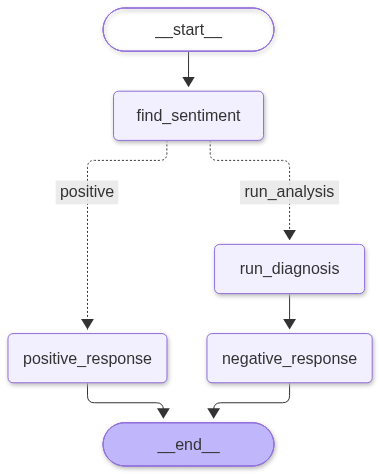

In [90]:
workflow

In [91]:
good_review= """This is awesome software . I really liked te UI and the responsiveness is also very good. Great work Devs"""

bad_review= """The software is very bad in terms of UX . Also have multiple bugs. The login page is not working . Not expecting these kind of basic flaws."""

initial_state= {"review": good_review}

final_state= workflow.invoke(initial_state)

In [92]:
print('=' * 60)
print(f"FEEDBACK PROCESSING RESULT [{final_state["sentiment"].upper()}]")
print('=' * 60)
print(f"\n Customer Review:\n  \"{final_state['review'].strip()}\"")
print(f"\n Sentiment Detected: {final_state.get('sentiment', 'N/A').capitalize()}")

if 'diagnosis' in final_state and final_state['diagnosis']:
    diag = final_state['diagnosis']
    print('\n  Diagnosis Breakdown:')
    print(f"   • Issue Type : {diag.get('issue_type', 'N/A')}")
    print(f"   • Tone       : {diag.get('tone', 'N/A')}")
    print(f"   • Urgency    : {diag.get('urgency', 'N/A')}")

print(f"\n Generated Response:\n  {final_state.get('response', 'N/A').strip()}")
print('\n' + '=' * 60)


FEEDBACK PROCESSING RESULT [POSITIVE]

 Customer Review:
  "This is awesome software . I really liked te UI and the responsiveness is also very good. Great work Devs"

 Sentiment Detected: Positive

 Generated Response:
  Thank you for your kind words! We're glad you found our software awesome. The user interface is indeed very intuitive, and we're proud of the responsive nature of our application. We're always striving to improve and enhance our products, and we appreciate your feedback. Keep using our software and let us know if you have any more questions or concerns!

